## 365Data Science-Resal Estate Market Analysis


## Importing data


In [1211]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick



In [1212]:
customers=pd.read_csv("customers.csv",parse_dates=['birth_date'])

In [1213]:
customers.info()
#all columns have non null values

<class 'pandas.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Unnamed: 0         162 non-null    int64         
 1   ﻿customerid        162 non-null    str           
 2   entity             162 non-null    str           
 3   name               162 non-null    str           
 4   surname            162 non-null    str           
 5   birth_date         155 non-null    datetime64[us]
 6   sex                155 non-null    str           
 7   country            162 non-null    str           
 8   state              154 non-null    str           
 9   purpose            162 non-null    str           
 10  deal_satisfaction  162 non-null    int64         
 11  mortgage           162 non-null    str           
 12  source             162 non-null    str           
dtypes: datetime64[us](1), int64(2), str(10)
memory usage: 25.1 KB


In [1214]:
customers.head(10)

,Unnamed: 0,﻿customerid,entity,name,surname,birth_date,sex,country,state,purpose,deal_satisfaction,mortgage,source
0,0,C0110,Individual,Kareem,Liu,1968-05-11,F,USA,California,Home,4,Yes,Website
1,1,C0010,Individual,Trystan,Oconnor,1962-11-26,M,USA,California,Home,1,No,Website
2,2,C0132,Individual,Kale,Gay,1959-04-07,M,USA,California,Home,4,Yes,Agency
3,3,C0137,Individual,Russell,Gross,1959-11-25,M,USA,California,Home,5,No,Website
4,4,C0174,Company,Marleez,Co,NaT,NaN,USA,California,Investment,5,No,Website
5,5,C0088,Individual,Yurem,Wright,1957-03-06,M,USA,California,Home,3,Yes,Website
6,6,C0079,Individual,Xavier,Faulkner,1947-05-24,M,Canada,NaN,Investment,5,No,Website
7,7,C0149,Individual,Kayden,Olsen,1969-10-17,F,USA,California,Home,5,No,Website
8,8,C0064,Individual,Joaquin,Mullins,1975-10-05,M,USA,California,Investment,5,No,Agency
9,9,C0068,Individual,Nicolas,Navarro,1966-06-17,M,USA,Oregon,Investment,3,No,Agency


In [1215]:
customers.shape
customers['country']=customers['country'].str.strip()
customers['mortgage'].isna().sum()

np.int64(0)

In [1216]:
customers.drop(columns=['Unnamed: 0'],inplace=True)

In [1217]:
customers.columns = customers.columns.str.replace('\ufeff', '', regex=False)
customers.columns = customers.columns.str.strip()
print(customers.columns)

Index(['customerid', 'entity', 'name', 'surname', 'birth_date', 'sex',
       'country', 'state', 'purpose', 'deal_satisfaction', 'mortgage',
       'source'],
      dtype='str')


In [1218]:
customers.describe()


,birth_date,deal_satisfaction
count,155,162.000000
mean,1961-08-27 14:42:34.838710,3.456790
min,1931-02-13 00:00:00,1.000000
25%,1952-10-11 12:00:00,3.000000
50%,1963-07-15 00:00:00,4.000000
75%,1970-12-29 00:00:00,5.000000
max,1986-06-21 00:00:00,5.000000
std,NaN,1.333276


# Analysing the Properties table

In [1219]:

properties=pd.read_csv("properties.csv",parse_dates=['date_sale']) 
properties.columns = properties.columns.str.strip()
properties.columns = properties.columns.str.replace('\ufeff', '', regex=False)

In [1220]:
properties.info()


<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  267 non-null    int64  
 1   id          267 non-null    int64  
 2   building    267 non-null    int64  
 3   date_sale   267 non-null    str    
 4   type        267 non-null    str    
 5   property#   267 non-null    int64  
 6   area        267 non-null    float64
 7   price       267 non-null    str    
 8   status      267 non-null    str    
 9   customerid  195 non-null    str    
dtypes: float64(1), int64(4), str(5)
memory usage: 31.0 KB


In [1221]:
properties.describe()
properties.drop(columns=['Unnamed: 0'],inplace=True)
properties.rename(columns={'property#':'property_no'},inplace=True)


In [1222]:
properties.head(15)

,id,building,date_sale,type,property_no,area,price,status,customerid
0,1030,1,11/1/2005,Apartment,30,743.09,"$246,172.68",Sold,C0028
1,1029,1,10/1/2005,Apartment,29,756.21,"$246,331.90",Sold,C0027
2,2002,2,7/1/2007,Apartment,2,587.28,"$209,280.91",Sold,C0112
3,2031,2,12/1/2007,Apartment,31,1604.75,"$452,667.01",Sold,C0160
4,1049,1,11/1/2004,Apartment,49,1375.45,"$467,083.31",Sold,C0014
5,3011,3,9/1/2007,Apartment,11,675.19,"$203,491.85",Sold,C0125
6,3026,3,9/1/2007,Apartment,26,670.89,"$212,520.83",Sold,C0125
7,3023,3,1/1/2008,Apartment,23,720.81,"$198,591.85",Sold,C0166
8,1031,1,6/1/2006,Apartment,31,782.25,"$265,467.68",Sold,C0034
9,4023,4,3/1/2006,Apartment,23,794.52,"$235,633.26",Sold,C0170


In [1223]:
properties.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           267 non-null    int64  
 1   building     267 non-null    int64  
 2   date_sale    267 non-null    str    
 3   type         267 non-null    str    
 4   property_no  267 non-null    int64  
 5   area         267 non-null    float64
 6   price        267 non-null    str    
 7   status       267 non-null    str    
 8   customerid   195 non-null    str    
dtypes: float64(1), int64(3), str(5)
memory usage: 28.9 KB


In [1224]:
properties['building'].isna().sum()

np.int64(0)

# Merging two tables using left join


In [1225]:
customers['customerid'] = customers['customerid'].str.strip()
properties['customerid'] = properties['customerid'].str.strip()
df=properties.merge(customers,on='customerid',how='left')

In [1226]:
df.shape

(267, 20)

In [1227]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 267 non-null    int64         
 1   building           267 non-null    int64         
 2   date_sale          267 non-null    str           
 3   type               267 non-null    str           
 4   property_no        267 non-null    int64         
 5   area               267 non-null    float64       
 6   price              267 non-null    str           
 7   status             267 non-null    str           
 8   customerid         195 non-null    str           
 9   entity             195 non-null    str           
 10  name               195 non-null    str           
 11  surname            195 non-null    str           
 12  birth_date         178 non-null    datetime64[us]
 13  sex                178 non-null    str           
 14  country            19

In [1228]:
df= df.apply(lambda x: x.str.strip()if x.dtype=='str' else x)
df['price'].dtype

<StringDtype(na_value=nan)>

# Statiscal Analysis

In [1229]:

df['price']=df['price'].str.replace('$','',regex=False).str.replace(',','',regex=False).str.strip()

In [1230]:
df['price']=df['price'].astype(float)
df['mortgage'] = (
    df['mortgage']
    .map({'Yes': 1, 'No': 0})
    .fillna(0)
    .astype(int)
)
df['mortgage'].value_counts()

mortgage
0    205
1     62
Name: count, dtype: int64

In [1231]:
df.describe()

,id,building,property_no,area,price,birth_date,deal_satisfaction,mortgage
count,267.000000,267.000000,267.000000,267.000000,267.000000,178,195.000000,267.000000
mean,2975.142322,2.947566,27.580524,936.221311,281171.901386,1961-01-08 11:35:43.820225,3.600000,0.232210
min,1002.000000,1.000000,1.000000,410.710000,117564.070000,1931-02-13 00:00:00,1.000000,0.000000
25%,2015.500000,2.000000,14.500000,756.210000,217553.055000,1951-05-04 06:00:00,3.000000,0.000000
50%,3024.000000,3.000000,28.000000,798.280000,249075.660000,1962-09-23 00:00:00,4.000000,0.000000
75%,4031.500000,4.000000,40.000000,1121.950000,326964.855000,1970-07-09 06:00:00,5.000000,0.000000
max,5052.000000,5.000000,59.000000,1942.500000,538271.740000,1986-06-21 00:00:00,5.000000,1.000000
std,1392.197474,1.391794,15.361437,284.894858,89119.121005,NaN,1.340872,0.423035


# Breakdown by types of Building

In [1232]:
priceByType=df[df['status']=='Sold'].groupby(['building']).agg(#"type",entity
    total_sold=("id","count"),
    deal_satisfaction=("deal_satisfaction","mean"),
    mortgage=("mortgage","sum"),
    avg_price=("price","mean"),
    avg_area=('area','mean')
).round(2)

In [1233]:
priceByType

,total_sold,deal_satisfaction,mortgage,avg_price,avg_area
building,,,,,
1,46,3.63,14,275218.99,927.09
2,54,3.52,18,278966.22,922.19
3,53,3.57,15,259241.12,870.26
4,23,3.87,9,274722.05,933.58
5,19,3.53,6,250373.86,812.31


# Breakdown by COUNTRY

In [1234]:
priceByCountry=df[df['status']=='Sold'].groupby(["country"]).agg(
    total_sold=("id","count"),
    avg_satisfaction_rate=("deal_satisfaction","mean"),
    mortgage=("mortgage","sum"),
    avg_price=("price","mean")
).round(2)

In [1235]:
priceByCountry

,total_sold,avg_satisfaction_rate,mortgage,avg_price
country,,,,
Belgium,2,3.00,0,229075.47
Canada,7,5.00,0,274069.38
Denmark,1,1.00,0,257183.48
Germany,1,5.00,0,205098.21
Mexico,1,3.00,0,338181.18
Russia,4,2.50,1,278828.84
UK,2,4.00,0,220142.68
USA,177,3.58,61,270096.27


In [1236]:
#Normalize=True in value_counts give proportion of the total
solddf=df[df['status']=='Sold']
country_frequency=round(solddf['country'].value_counts(normalize=True)*100, 2)

In [1237]:
country_frequency

country
USA        90.77
Canada      3.59
Russia      2.05
UK          1.03
Belgium     1.03
Denmark     0.51
Germany     0.51
Mexico      0.51
Name: proportion, dtype: float64

# By State

In [1238]:
priceBystate=df[df['status']=='Sold'].groupby(["state"]).agg(
    total_sold=("id","count"),
    avg_satisfaction_rate=("deal_satisfaction","mean"),
    mortgage_rate=("mortgage","mean"),
    avg_price=("price","mean")
).round(2)


In [1239]:
print(priceBystate)

            total_sold  avg_satisfaction_rate  mortgage_rate  avg_price
state                                                                  
Arizona             11                   3.36           0.27  259526.95
California         120                   3.75           0.34  278680.74
Colorado            11                   3.18           0.45  233662.46
Kansas               1                   3.00           0.00  252185.99
Nevada              17                   3.24           0.47  277649.33
Oregon              11                   3.09           0.09  236593.32
Utah                 5                   3.20           0.20  237755.28
Virginia             4                   4.50           0.50  215144.19
Wyoming              1                   3.00           0.00  204286.67


# frequency distribution

In [1240]:
state_freq = df['state'].value_counts().to_frame('frequency')

In [1241]:
state_freq['rel_freq']=round(df['state'].value_counts(normalize=True)*100,2)

In [1242]:
state_freq['cum_freq']=state_freq['rel_freq'].cumsum()

In [1243]:
state_freq

,frequency,rel_freq,cum_freq
state,,,
California,120,66.30,66.30
Nevada,17,9.39,75.69
Arizona,11,6.08,81.77
Oregon,11,6.08,87.85
Colorado,11,6.08,93.93
Utah,5,2.76,96.69
Virginia,4,2.21,98.90
Kansas,1,0.55,99.45
Wyoming,1,0.55,100.00


In [1244]:
df['source'].value_counts()

source
Website    119
Agency      59
Client      17
Name: count, dtype: int64

In [1245]:
df['type'].value_counts()

type
Apartment    259
Office         8
Name: count, dtype: int64

In [1246]:
round(pd.crosstab(df['state'],df['mortgage'],normalize=True)*100,2)

mortgage,0,1
state,,
Arizona,4.42,1.66
California,43.65,22.65
Colorado,3.31,2.76
Kansas,0.55,0.00
Nevada,4.97,4.42
Oregon,5.52,0.55
Utah,2.21,0.55
Virginia,1.10,1.10
Wyoming,0.55,0.00


# Analyzing Age

In [1247]:
df['age']=(pd.Timestamp.today().year - df['birth_date'].dt.year).astype('Int64')

##create Age interval-binning

In [1248]:
df['Age_group']=pd.cut(df['age'],bins=[19,26,31,36,42,48,54,60,65,71,76,81,86,100],
                       labels=['19-25','26-30','31-35','36-41','42-47','48-53','54-59','60-64','65-70','71-75','76-80','81-85','86+'])

##sold by age

In [1249]:
df_soldbyAge=df[df['status']=='Sold'].groupby("Age_group").agg(
    total_purchased=("id","count"),
    avg_satisfaction=("deal_satisfaction","mean"),
    mortgage_count=("mortgage","sum"),
    avg_price=("price","mean")
).reset_index().round(2)

In [1250]:
df_soldbyAge['rel_freq']=round((df_soldbyAge['total_purchased']/df_soldbyAge['total_purchased'].sum())*100,2)

In [1251]:
df_soldbyAge['cum_freq']=df_soldbyAge['rel_freq'].cumsum()

In [1252]:
df_soldbyAge

,Age_group,total_purchased,avg_satisfaction,mortgage_count,avg_price,rel_freq,cum_freq
0,36-41,3,3.00,2,302706.87,1.69,1.69
1,42-47,11,4.27,3,314439.35,6.18,7.87
2,48-53,27,3.37,8,276982.80,15.17,23.04
3,54-59,30,3.20,12,286367.21,16.85,39.89
4,60-64,24,3.25,9,276859.58,13.48,53.37
5,65-70,26,3.54,12,249417.00,14.61,67.98
6,71-75,14,3.29,2,254257.81,7.87,75.85
7,76-80,19,4.37,3,268682.72,10.67,86.52
8,81-85,10,3.80,3,252447.86,5.62,92.14
9,86+,14,3.36,4,248343.49,7.87,100.01


# Analyzing property prices

In [1253]:
df['property_type']=pd.qcut(df['price'],q=4,labels=['Budget','Mid','Premium','Luxury'])

In [1254]:
df['price_group']=pd.qcut(df['price'],q=10)

In [1255]:
df['price_group'].value_counts()

price_group
(117564.069, 198969.2]      27
(198969.2, 210940.622]      27
(223451.298, 234403.67]     27
(234403.67, 249075.66]      27
(267632.252, 308973.298]    27
(354969.366, 411702.226]    27
(411702.226, 538271.74]     27
(210940.622, 223451.298]    26
(249075.66, 267632.252]     26
(308973.298, 354969.366]    26
Name: count, dtype: int64

In [1256]:
df_price=df.groupby("property_type").agg(
    total_count=("id","count"),
    avg_satisfaction=("deal_satisfaction","mean"),
    mortgage_count=("mortgage","sum"),
    avg_price=("price","mean"),
    total_sold=("status",lambda x: (x=='Sold').sum())
).round(2)

In [1257]:
df_price

,total_count,avg_satisfaction,mortgage_count,avg_price,total_sold
property_type,,,,,
Budget,67,3.60,16,197214.60,55
Mid,67,3.64,14,232413.59,53
Premium,66,3.48,18,281634.46,48
Luxury,67,3.69,14,413431.87,39


# Relationship between Age and Property

In [1258]:
df['age'].corr(df['price'])

np.float64(-0.167540606760857)

In [1259]:
#weak correlation between age and price..no significant relationship

# Data Visualization

##deal satisfaction by country

In [1260]:
df_sold=df[df['status']=='Sold']
sold=195
unsold=72

In [1261]:
df_satByCountry=round(df.groupby("country")['deal_satisfaction'].mean().reset_index(),2)

In [1262]:
df_satByCountry

,country,deal_satisfaction
0,Belgium,3.00
1,Canada,5.00
2,Denmark,1.00
3,Germany,5.00
4,Mexico,3.00
5,Russia,2.50
6,UK,4.00
7,USA,3.58


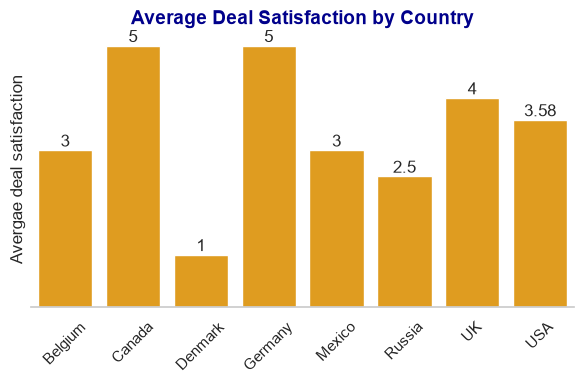

In [1263]:
plt.figure(figsize=(6,4))
sns.set_palette("pastel")

sns.set_context("notebook")
fontdict={
        'fontsize': 14,
        'fontweight': 'bold',
        'color': 'darkblue'
    }
plt.title("Average Deal Satisfaction by Country", fontdict=fontdict)
ax=sns.barplot(data=df_satByCountry,x='country',y='deal_satisfaction',color='orange')
sns.despine(left=True) # remove the top and right border,customizable )
ax.set_xlabel('')
ax.set_ylabel('Avergae deal satisfaction')
ax.bar_label(ax.containers[0])

plt.xticks(rotation=45)   #rotates the x labesl to 45degree
plt.yticks([])
plt.tight_layout()   # the labels are not overwritten on each other
plt.show()

##deal satisfaction by state

In [1264]:
df_satByState=round(df.groupby("state")['deal_satisfaction'].mean(),2).sort_values(ascending=False).to_frame()

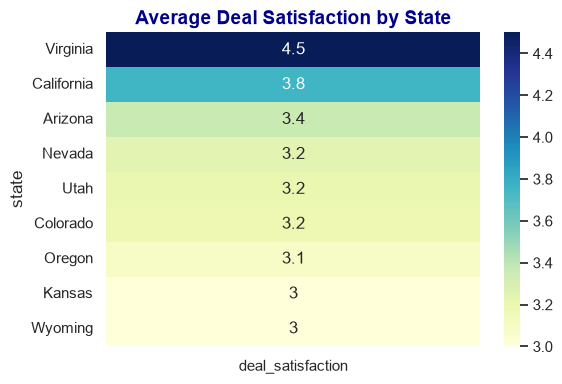

In [1265]:
plt.figure(figsize=(6,4))
plt.title("Average Deal Satisfaction by State",fontdict=fontdict)
sns.heatmap(annot=True,data=df_satByState,cmap='YlGnBu')
plt.tight_layout()
plt.show()

##Monthly revenue of the company

In [1273]:
df_sold['date_sale']=pd.to_datetime(df_sold['date_sale'])
df_sold['date_sale_YM']=df_sold['date_sale'].dt.to_period('M').astype(str)

revenue_df=round(df_sold.groupby(["date_sale_YM"])['price'].sum(),2).to_frame().reset_index()
revenue_df.head(5)



,date_sale_YM,price
0,2004-03,697655.03
1,2004-06,606778.27
2,2004-08,620437.99
3,2004-10,1214785.83
4,2004-11,1257352.68


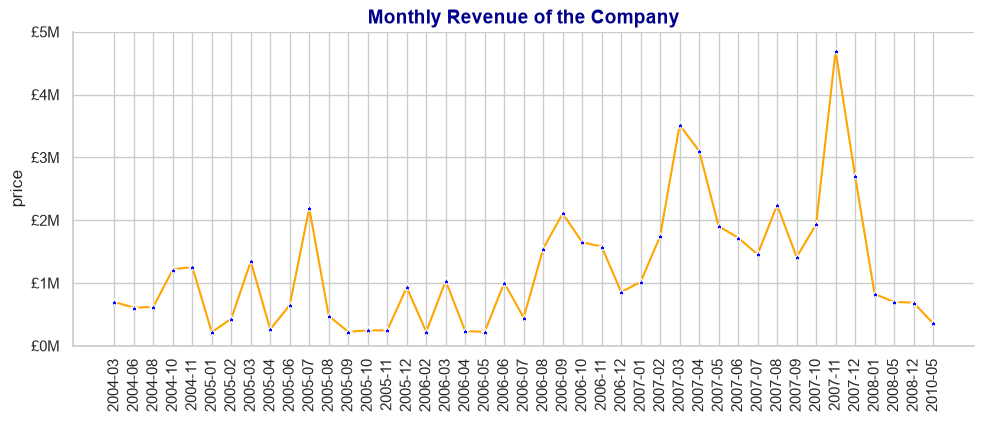

In [1267]:
plt.figure(figsize=(10,4))
plt.title("Monthly Revenue of the Company",fontdict=fontdict)
ax5=sns.lineplot(data=revenue_df,x='date_sale_YM',y='price',markerfacecolor='blue',marker='*',color='orange')
plt.ylim(0,5000000)
plt.yticks(range(0, 5500000, 1000000))
plt.xlabel('')
ax5.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'£{x/1e6:.0f}M')
)

sns.despine()
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()


##Apartments sold in each state


In [1268]:
Apartment_Sold=df_sold.groupby("state")['id'].count().to_frame()
Apartment_Sold['rel_freq']=round((Apartment_Sold['id']/Apartment_Sold['id'].sum()),4)
Apartment_Sold['cum_freq']=Apartment_Sold['rel_freq'].cumsum()

In [1269]:
Apartment_Sold

,id,rel_freq,cum_freq
state,,,
Arizona,11,0.0608,0.0608
California,120,0.6630,0.7238
Colorado,11,0.0608,0.7846
Kansas,1,0.0055,0.7901
Nevada,17,0.0939,0.8840
Oregon,11,0.0608,0.9448
Utah,5,0.0276,0.9724
Virginia,4,0.0221,0.9945
Wyoming,1,0.0055,1.0000


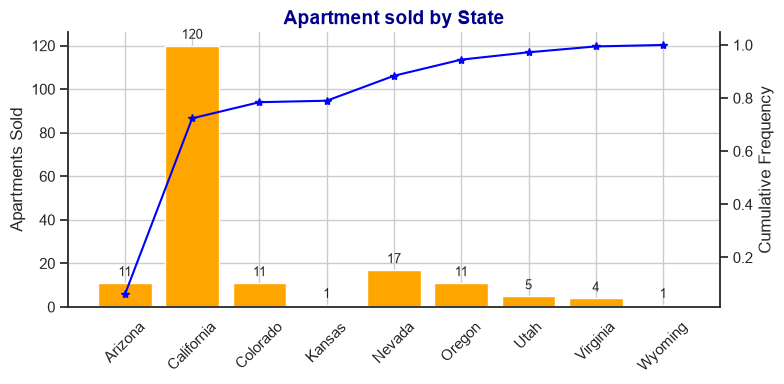

In [1271]:
fig,ax1=plt.subplots(figsize=(8,4))#makes a blank picture that is 8 inches wide and 4 inches tall.
bars=ax1.bar(Apartment_Sold.index,Apartment_Sold['id'],color='orange')#axis 1 is bar
ax1.bar_label(
    bars,padding=3,
    fontsize=9,
    fmt='%d'
)

sns.set_style("white")


ax2 = ax1.twinx()# adds a second axis on the right side.
ax2.plot( Apartment_Sold.index,
    Apartment_Sold['cum_freq'],
    color='blue',marker='*')
plt.title("Apartment sold by State",fontdict=fontdict)
ax1.set_ylabel("Apartments Sold")
ax2.set_ylabel("Cumulative Frequency")
sns.despine(top=True,right=False)
ax1.tick_params(axis='x', labelrotation=45)
plt.tight_layout()

plt.show()

##Age distribution of the customers


In [ ]:
plt.figure(figsize=(6,4))
plt.title("Age distribution of Customers",fontdict=fontdict)
ax3=sns.histplot(data=df,x='age',bins=10)
plt.xlabel("Age(in Years)")

sns.despine()
plt.show()

##Sales per Year by Building Type

In [ ]:
df_sold['Sold_Year']=df_sold['date_sale'].dt.year.astype(int)
sales_byType=df_sold.groupby(["Sold_Year",'building'])['price'].sum().to_frame().unstack(fill_value=0)

In [ ]:
sales_byType

In [ ]:
sales_byBuildingType=df_sold.groupby(["Sold_Year",'building'])['price'].sum().to_frame().unstack(fill_value=0)
sales_byBuildingType

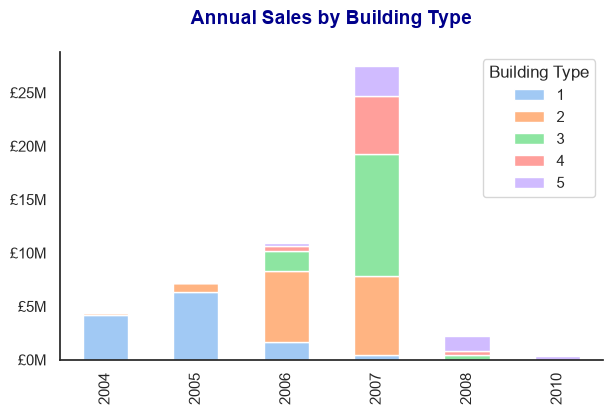

In [1272]:

sales_byType.columns = sales_byType.columns.get_level_values(-1)
ax4=sales_byType.plot(kind='bar',stacked=True,figsize=(7,4))
plt.xlabel("")

sns.despine()
ax4.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f'£{x/1e6:.0f}M')
)
plt.legend(title='Building Type')
ax4.set_title(
    "Annual Sales by Building Type",
    fontdict=fontdict,
    pad=20
)
#plt.tight_layout()
plt.show()


In [ ]:
#Unsold Price Range

In [ ]:
df_unsold=df[df['status'] !='Sold']

In [ ]:
df_unsold['unsold_price_group']=pd.qcut(df_unsold['price'],q=10)


In [ ]:
df_unsold['unsold_price_group'].value_counts()